# Where did Germany's snow go?
### From DWD's snow grids to the data behind the map

This notebook explores the German weather service's (DWD) yearly snow grids, 1951 to 2025, step by step: from one file to an average for two thirty-year periods, drawn as one line every 6 km across Germany. Every step shows its result.

---

> **Why thirty-year averages and not single years?** Single winters swing widely: in 2010 Germany averaged 91 snow days, in 2020 just 9.
> The World Meteorological Organization averages thirty years to describe a climate, and calls those averages climate normals.
> 1961 to 1990 is its reference period, 1991 to 2020 its current one.

---

### Setup

The map's colours, so the charts here look like the site.

In [1]:
# Setup
import gzip
import json
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# run from the project folder, or from notebooks/
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Color palette (the map's)
COLORS = {
    'paper': '#f7f3ec',
    'ink': '#21201c',
    'muted': '#6f675c',
    'rust': '#b5432e',
}

# Chart styling
plt.rcParams['figure.facecolor'] = COLORS['paper']
plt.rcParams['axes.facecolor'] = COLORS['paper']
plt.rcParams['axes.edgecolor'] = COLORS['muted']
plt.rcParams['axes.labelcolor'] = COLORS['ink']
plt.rcParams['text.color'] = COLORS['ink']
plt.rcParams['xtick.color'] = COLORS['muted']
plt.rcParams['ytick.color'] = COLORS['muted']
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# paper for no snow, ink for a lot, like the map's lines
snow_cmap = LinearSegmentedColormap.from_list('snow', [COLORS['paper'], COLORS['ink']])

### Data Loading

DWD publishes one file per year, 1951 to 2025, about 22 MB in all, as open data (CC BY 4.0). Any year not yet in `raw/grids/` is downloaded from DWD.

In [2]:
# Download any year that's missing
URL = "https://opendata.dwd.de/climate_environment/CDC/grids_germany/annual/snowcover_days"
YEARS = list(range(1951, 2026))
os.makedirs("raw/grids", exist_ok=True)

for year in YEARS:
    path = f"raw/grids/snow_{year}.asc.gz"
    if not os.path.exists(path):
        urllib.request.urlretrieve(f"{URL}/grids_germany_annual_snowcover_days_{year}_17.asc.gz", path)

print(f"{len(os.listdir('raw/grids'))} yearly files in raw/grids/")

75 yearly files in raw/grids/


## Step 1: One file, as published

2010, the snowiest year in the record. The first lines of the file:

In [3]:
# The first lines of one file, as text
with gzip.open("raw/grids/snow_2010.asc.gz", "rt") as f:
    for _ in range(6):
        print(f.readline().strip())

NCOLS 654
NROWS 866
XLLCORNER 3280414.711633467
YLLCORNER 5237500.62890625
CELLSIZE 1000
NODATA_VALUE -999


Six lines of header, then the numbers: 654 columns by 866 rows, each cell 1,000 m across, one square kilometre. `-999` marks squares outside Germany.

What each number counts, in DWD's description of the data: *"Number of days with snow cover. Definition of snow cover: snow depth >= 1 cm at morning reading"*.

In [4]:
# One year's map: snow days for every 1 km square, -999 = outside Germany
def read_map(year):
    grid = np.loadtxt(f"raw/grids/snow_{year}.asc.gz", skiprows=6)
    grid[grid == -999] = np.nan
    return grid

grid_2010 = read_map(2010)
print(f"Grid: {grid_2010.shape[0]} rows x {grid_2010.shape[1]} columns")
print(f"Squares inside Germany: {np.sum(~np.isnan(grid_2010)):,}")
print(f"Squares outside: {np.sum(np.isnan(grid_2010)):,}")

Grid: 866 rows x 654 columns
Squares inside Germany: 358,303
Squares outside: 208,061


358,303 squares of Germany. `-999` becomes `nan` ("no number"), not zero: counted as zero, the sea would look like land without snow and pull every average down.

To look up a city, `src/data/places.json` has each one's position on the grid (from BKG's official place names, GN250). The map puts a city's dot on the nearest line, so the lookup does the same.

In [5]:
# The six cities on the map, in 2010
places = pd.read_json("src/data/places.json").set_index("name")

def city_square(name):
    # the square under the city's dot: the nearest line (every 6 km) and point (every 2 km)
    line = round(places.loc[name, "row"] / 6) * 6
    point = round(places.loc[name, "col"] / 2) * 2
    return line, point

for city in ["Hamburg", "Berlin", "Cologne", "Frankfurt", "Dresden", "Munich"]:
    print(f"{city:10s} {grid_2010[city_square(city)]:.0f} snow days")

Hamburg    94 snow days
Berlin     87 snow days
Cologne    58 snow days
Frankfurt  64 snow days
Dresden    83 snow days
Munich     86 snow days


Mornings in 2010 with at least 1 cm of snow on the ground. A snowy winter even in the lowlands: Cologne, the least snowy of the six, still had 58.

## Step 2: One year as a picture

The same 2010 grid, drawn. Darker means more snow days.

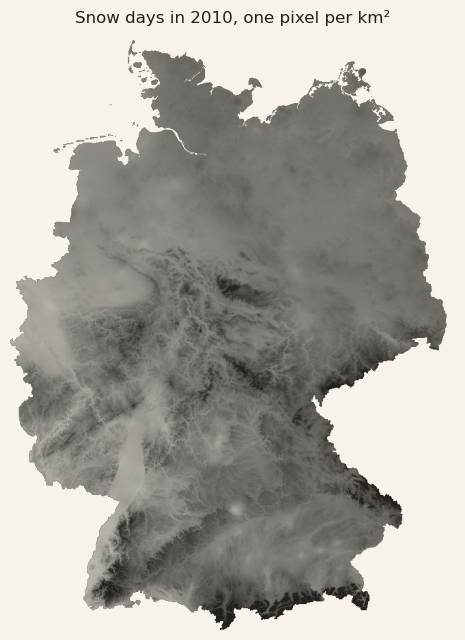

In [6]:
# 2010 as a picture
fig, ax = plt.subplots(figsize=(5, 6.5))
ax.imshow(grid_2010, cmap=snow_cmap, vmin=0, vmax=150)
ax.set_title('Snow days in 2010, one pixel per km²', fontweight='medium', pad=12)
ax.axis('off')
plt.tight_layout()
plt.show()

The Alps, the Black Forest, the Harz and the mountains along the Czech border are darkest.

## Step 3: Germany's average, every year

All 75 files. For each year: Germany's average, and the map added to a running total for its period, so the thirty years can be averaged in Step 5. Berlin's square is kept for Step 4.

In [7]:
# Read all 75 years
PERIODS = {
    "1961-1990": (1961, 1990),
    "1991-2020": (1991, 2020),
}

year_averages = []
period_totals = {"1961-1990": 0, "1991-2020": 0}
BERLIN = city_square("Berlin")
berlin = {}

for year in YEARS:
    grid = read_map(year)
    year_averages.append(np.nanmean(grid))  # nanmean skips the squares outside Germany
    berlin[year] = grid[BERLIN]
    for period, (first, last) in PERIODS.items():
        if first <= year <= last:
            period_totals[period] = period_totals[period] + grid

yearly = pd.DataFrame({'year': YEARS, 'snow_days': year_averages})
print(f"Read {len(yearly)} years")
yearly.round(1).head()

Read 75 years


,year,snow_days
0,1951,26.5
1,1952,61.5
2,1953,43.5
3,1954,35.5
4,1955,60.7


In [8]:
# Snowiest and least snowy years
print("Least snow:")
print(yearly.nsmallest(3, 'snow_days').round(1).to_string(index=False))
print("\nMost snow:")
print(yearly.nlargest(3, 'snow_days').round(1).to_string(index=False))

Least snow:
 year  snow_days
 2020        8.8
 1989        9.1
 2025       12.2

Most snow:
 year  snow_days
 2010       90.6
 1970       84.4
 1969       83.0


From 9 days to 91. Two of the three least snowy years are from the last six years; two of the three snowiest are from around 1970.

Each year against the 1961 to 1990 average, as on the method page:

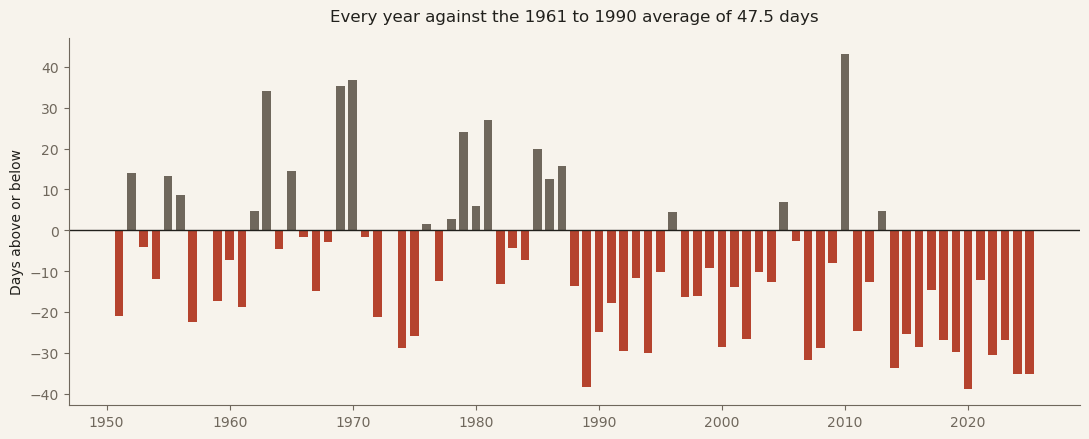

In [9]:
# Every year against the 1961 to 1990 average
baseline = yearly[(yearly['year'] >= 1961) & (yearly['year'] <= 1990)]['snow_days'].mean()
difference = yearly['snow_days'] - baseline

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(yearly['year'], difference, color=[COLORS['muted'] if d >= 0 else COLORS['rust'] for d in difference], width=0.7)
ax.axhline(0, color=COLORS['ink'], linewidth=1)
ax.set_ylabel('Days above or below')
ax.set_title(f'Every year against the 1961 to 1990 average of {baseline:.1f} days', fontweight='medium', pad=12)
plt.tight_layout()
plt.show()

Grey above the average, rust below. Until the late 1980s the years fall on both sides; after, almost every year is below.

## Step 4: One square, thirty years

The map's numbers are thirty-year averages, square by square. One by hand: the square under Berlin's dot, 1961 to 1990.

In [10]:
# Berlin's 30 values, 1961 to 1990
values = [int(berlin[year]) for year in range(1961, 1991)]
print(values)
print(f"\nSum: {sum(values)}")
print(f"Average: {sum(values)} / 30 = {sum(values) / 30:.2f}")
print(f"Rounded to whole days: {np.floor(sum(values) / 30 + 0.5):.0f}")

[16, 29, 77, 29, 58, 48, 19, 41, 88, 92, 31, 14, 28, 5, 5, 44, 16, 26, 68, 49, 56, 18, 30, 16, 52, 52, 55, 21, 3, 12]

Sum: 1098
Average: 1098 / 30 = 36.60
Rounded to whole days: 37


37, the number next to Berlin on the map for 1961 to 1990. The single years run from 3 to 92 days.

## Step 5: Every square at once

The same sum and division by thirty, for the whole grid at once.

In [11]:
# Thirty-year averages, for every square
averages = {}
for period, (first, last) in PERIODS.items():
    averages[period] = period_totals[period] / (last - first + 1)

before = np.nanmean(averages["1961-1990"])
after = np.nanmean(averages["1991-2020"])
print(f"Germany, 1961 to 1990: {before:.2f} snow days a year")
print(f"Germany, 1991 to 2020: {after:.2f} snow days a year")
print(f"Change: {(1 - after / before):.1%} fewer")
print(f"\nBerlin: {averages['1961-1990'][BERLIN]:.1f} -> {averages['1991-2020'][BERLIN]:.1f}")

# how many squares lost snow days?
both = ~np.isnan(averages["1961-1990"])
fewer = np.sum(averages["1991-2020"][both] < averages["1961-1990"][both])
print(f"Squares with fewer snow days: {fewer:,} of {both.sum():,}")

Germany, 1961 to 1990: 47.52 snow days a year
Germany, 1991 to 2020: 31.54 snow days a year
Change: 33.6% fewer

Berlin: 36.6 -> 22.1
Squares with fewer snow days: 358,300 of 358,303


47.5 to 31.5, a third fewer, and not a few places pulling the average down: all but 3 of 358,303 squares have fewer snow days. Every square has a value in all thirty years of both periods.

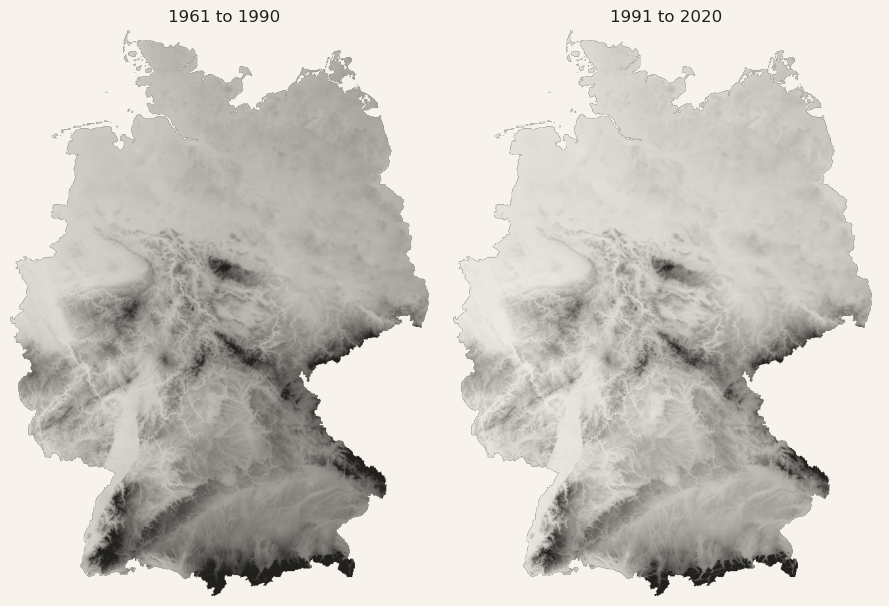

In [12]:
# The two periods side by side
fig, axes = plt.subplots(1, 2, figsize=(9, 6))
for ax, period in zip(axes, PERIODS):
    ax.imshow(averages[period], cmap=snow_cmap, vmin=0, vmax=120)
    ax.set_title(period.replace('-', ' to '), fontweight='medium')
    ax.axis('off')
plt.tight_layout()
plt.show()

Same scale on both. 1991 to 2020 is paler almost everywhere, the mountains included.

## Step 6: From a grid to lines

The map draws a line every 6 km from north to south, with a point every 2 km along it: every 6th row and every 2nd column of the grid, rounded to whole days.

In [13]:
# Keep every 6th row and every 2nd column
ROW_STEP = 6
COL_STEP = 2

points = {}
for period in PERIODS:
    points[period] = np.floor(averages[period][::ROW_STEP, ::COL_STEP] + 0.5)  # whole days, .5 rounds up

print(f"Lines: {points['1961-1990'].shape[0]}")
print(f"Points per line: {points['1961-1990'].shape[1]}")
print(f"Points inside Germany: {np.sum(~np.isnan(points['1961-1990'])):,} per period")

Lines: 145
Points per line: 327
Points inside Germany: 29,833 per period


145 lines, 29,833 points per period inside Germany. Each line on the map is one row of this. The line through the Harz, the one the map opens with:

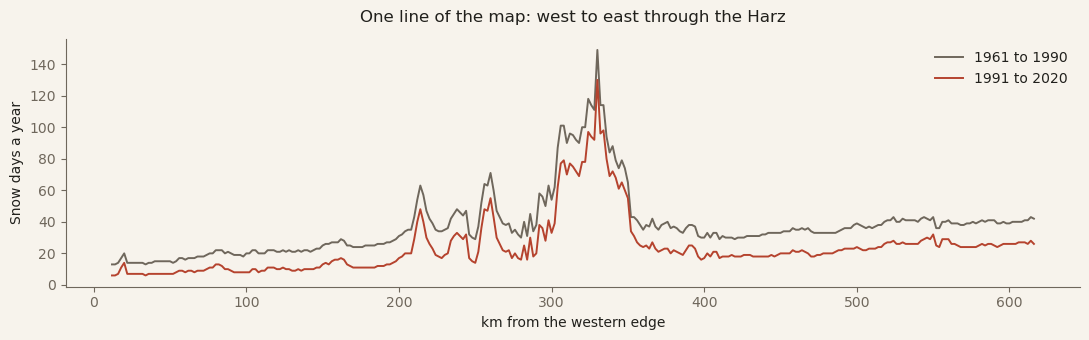

In [14]:
# The line through the Harz, both periods
HARZ_LINE = 60  # line number, north to south
x = np.arange(points['1961-1990'].shape[1]) * COL_STEP

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(x, points['1961-1990'][HARZ_LINE], color=COLORS['muted'], linewidth=1.4, label='1961 to 1990')
ax.plot(x, points['1991-2020'][HARZ_LINE], color=COLORS['rust'], linewidth=1.4, label='1991 to 2020')
ax.set_xlabel('km from the western edge')
ax.set_ylabel('Snow days a year')
ax.set_title('One line of the map: west to east through the Harz', fontweight='medium', pad=12)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

The peak is the Harz. 1991 to 2020 sits below 1961 to 1990 almost all the way across.

## What comes next

That's the exploring done. This notebook was for understanding the data, one step at a time.

For the map, the same steps run as scripts. A script runs from start to finish in one go, and it saves the result as small files the D3 site can load:

- `scripts/prepare.py`: Steps 5 and 6, the thirty-year averages and the lines
- `scripts/places.py`: the cities and mountains, from BKG, placed on DWD's grid
- `scripts/draw.mjs`: smooths the lines for drawing; the numbers people read stay as they are

---

## Notes

- Each square is DWD's estimate from its weather stations, not a measurement at that spot.
- The smoothing in `scripts/draw.mjs` only changes how the lines look; the numbers a reader sees are the whole-day values from Step 6.
- Nothing here tests why the snow went.

Sources and DWD's own description of the data: `METHODOLOGY.md`.

Place positions: © [BKG](https://www.bkg.bund.de) (2026) [dl-de/by-2-0](https://www.govdata.de/dl-de/by-2-0), [Datenquellen](https://sgx.geodatenzentrum.de/web_public/gdz/datenquellen/datenquellen_gn250.pdf), converted to DWD's grid.